# Free Sliders Interactive Notebook — Text to Audio (Stable Audio Open)

This notebook mirrors `T2I_interactive.ipynb` but targets the Stable Audio Open backbone. It runs on macOS Apple Silicon via the `mps` device or on CUDA / CPU automatically.

**Methods Available:**
- **FreeSliders**: Heun-step noise mixing during diffusion.
- **TE**: Linear interpolation of the dict-based audio conditioning.

## 1. Import Required Libraries

In [1]:
import os
import sys
import warnings
import importlib
from datetime import datetime

import torch
import torchaudio
import matplotlib.pyplot as plt
from IPython.display import Audio, display

warnings.filterwarnings("ignore", category=FutureWarning)

from methods.FreeSliders import FreeSliders
from methods.TE import TE
from utils.config_utils import load_config_from_yaml
from utils.prompt_utils import PromptSettings, load_prompts_from_yaml
from utils.utils import get_device

device = get_device()
print(f"Using device: {device}")

Using device: mps


## 2. Load Configuration and Prompts

In [2]:
config_file = "configs/config.yaml"
config = load_config_from_yaml(config_file)

audio_prompts_file = (
    config.audio.prompts_file if config.audio is not None else "configs/audio_prompts.yaml"
)
audio_prompts = load_prompts_from_yaml(audio_prompts_file, [])
print(f"Loaded {len(audio_prompts)} audio concepts from {audio_prompts_file}")
for p in audio_prompts:
    print(f"  - {p.tag}: {p.neutral!r}")

class NotebookLogger:
    def log_hparams(self, params): pass
    def add_tags(self, tag): pass
    def stop(self): pass
    def log(self, name, data, step=None): pass
    def log_audio(self, name, path): print(f"{name}: saved audio at {path}")
    def __getitem__(self, key): return self

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
logger = NotebookLogger()

Loaded 10 audio concepts from configs/audio_prompts.yaml
  - cat: 'A cat meowing'
  - ocean: 'ocean wave sounds'
  - car: 'car engine sound'
  - choir: 'choir singing a classical piece'
  - door: 'door slamming shut'
  - clapping: 'crowd clapping'
  - guitar: 'solo guitar'
  - barking: 'Dog barking'
  - rain: 'Rain falling'
  - crowd: 'crowd of people talking'


## 3. Load Stable Audio Open

First-time downloads of the model weights can take several minutes.

In [3]:
print("Loading Stable Audio Open...")
module_name = "base_models.BaseModel_StableAudio"
BaseModelClass = importlib.import_module(module_name).BaseModel
base_model = BaseModelClass(config, run_id)
print(f"Model loaded on {base_model.device} (dtype={base_model.weight_dtype}).")

Loading Stable Audio Open...
No module named 'flash_attn'
flash_attn not installed, disabling Flash Attention


/Users/hedizisling/code/Free_Sliders/.venv/lib/python3.9/site-packages/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


Model loaded on mps (dtype=torch.float32).


## 4. Choose Concepts and Encode Prompts

Pick which concepts from `audio_prompts.yaml` to run, or build your own `PromptSettings` here.

In [4]:
# Index into `audio_prompts` (or build a fresh PromptSettings list).
selected_indices = [0]
selected_prompts = [audio_prompts[i] for i in selected_indices]
for p in selected_prompts:
    print(f"\nTag: {p.tag}\n  neutral : {p.neutral}\n  positive: {p.positive}\n  negative: {p.negative}")

all_prompt_embeddings = base_model.encode_prompts(selected_prompts)
print(f"\nEncoded {len(all_prompt_embeddings)} prompt pairs")
base_model.delete_and_flush()


Tag: cat
  neutral : A cat meowing
  positive: A cat meowing loudly
  negative: A cat meowing softly


/Users/hedizisling/code/Free_Sliders/.venv/lib/python3.9/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(



Encoded 1 prompt pairs


## 5. Generation Parameters

In [5]:
selected_method = "FreeSliders"  # or "TE"

# Defaults below mirror the cluster runs:
#   FreeSliders: t=4, scales=±3, guidance2=1.0
#   TE        : t=4, scales=±1.5, guidance2=7.0
if selected_method == "FreeSliders":
    scales = [-16.0, 0.0, 16.0]
    guidance_scale_variation = 1.0
elif selected_method == "TE":
    scales = [-1.5, -0.5, 0.0, 0.5, 1.5]
    guidance_scale_variation = 7.0

num_images = 1
timestep_intervention = 4   # of 36 total Stable Audio Open steps
guidance_scale_neutral = 7.0
seed = 100

class Args:
    def __init__(self, scales, tag, method):
        self.num_images = num_images
        self.t = timestep_intervention
        self.scales = scales
        self.guidance = guidance_scale_neutral
        self.guidance2 = guidance_scale_variation
        self.BaseModel = "T2A"
        self.concept_tag = tag
        self.method = method

print(f"Method: {selected_method} | scales: {scales} | t={timestep_intervention} | guidance2={guidance_scale_variation}")

Method: FreeSliders | scales: [-20.0, 0.0, 20.0] | t=4 | guidance2=1.0


## 6. Run the Method

In [6]:
if selected_method == "FreeSliders":
    method_model = FreeSliders(base_model)
elif selected_method == "TE":
    method_model = TE(base_model)
else:
    raise ValueError(f"Unknown method: {selected_method}")

all_results = {}
for idx, prompt in zip(selected_indices, selected_prompts):
    args = Args(scales, prompt.tag, selected_method)
    text_embeddings = {"static": [all_prompt_embeddings[selected_indices.index(idx)]]}
    prompts = {"static": [prompt]}
    results = method_model(
        args=args,
        text_embeddings=text_embeddings,
        prompts=prompts,
        seed=seed,
        logger=logger,
    )
    all_results[prompt.tag] = results
    print(f"Finished {prompt.tag}")


Computing FreeSliders for - Tag: cat
Neutral Prompt: A cat meowing
Positive Prompt: A cat meowing loudly
Negative Prompt: A cat meowing softly
Running missing scales: [-20.0, 20.0]


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
Diffusing with scale 20.0: 100%|██████████| 32/32 [02:34<00:00,  4.82s/it]


Saved latents to T2A_sd_latents/FreeSliders/cat/7.0/1.0/4/1194.pkl
cat/audio_scale_-20.0: saved audio at ./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_-20.0.wav
cat/audio_scale_0.0: saved audio at ./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_0.0.wav
cat/audio_scale_20.0: saved audio at ./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_20.0.wav
Finished cat


## 7. Playback + Spectrograms

`log_and_evaluate` returns `(audio_decoded, contextual_clap, positive_clap, negative_clap, lpaps, waveform_paths)`. The `waveform_paths` dict maps each scale to the saved `.wav` on disk.


=== cat ===
scale=-20.0  (./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_-20.0.wav)


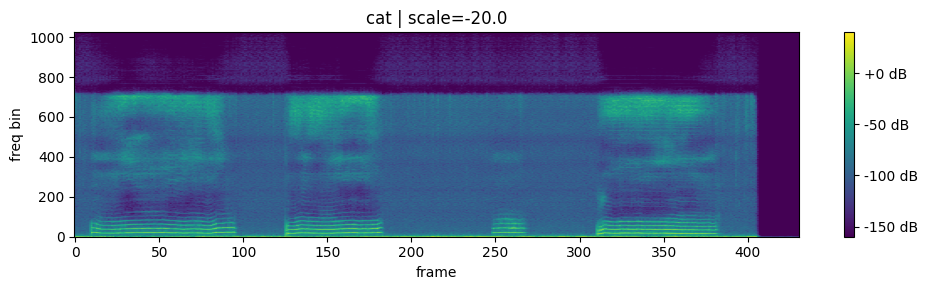

scale=0.0  (./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_0.0.wav)


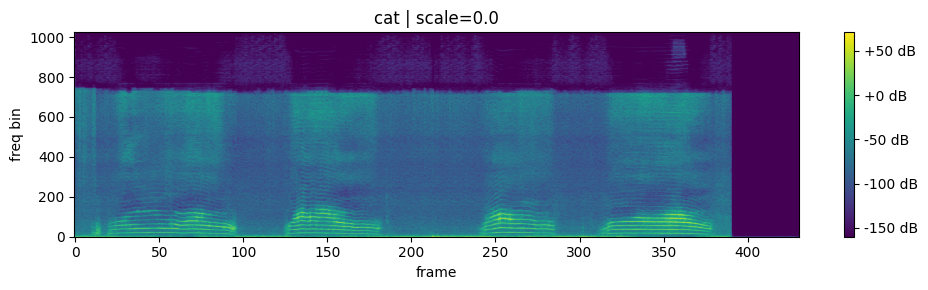

scale=20.0  (./outputs/FreeSliders/cat/A_cat_meowing/seed_1194/audio_output_scale_20.0.wav)


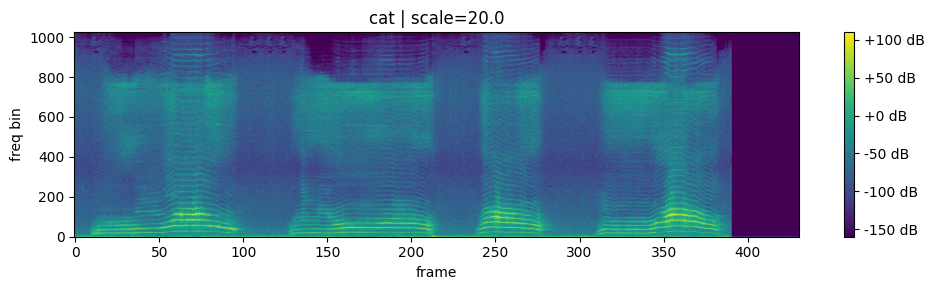

In [7]:
try:
    from base_models.stable_audio_tools.interface.aeiou import audio_spectrogram_image
    have_aeiou = True
except Exception:
    have_aeiou = False
    print("aeiou not available; falling back to torchaudio spectrogram.")

def show_spectrogram(waveform, sample_rate, title=""):
    if waveform.dim() == 2 and waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    spec = torchaudio.transforms.Spectrogram(n_fft=2048)(waveform)
    spec_db = torchaudio.functional.amplitude_to_DB(spec, multiplier=20.0, amin=1e-8, db_multiplier=0.0)
    plt.figure(figsize=(10, 3))
    plt.imshow(spec_db[0].cpu().numpy(), aspect="auto", origin="lower")
    plt.title(title)
    plt.xlabel("frame"); plt.ylabel("freq bin")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout(); plt.show()

for tag, results in all_results.items():
    if results is None:
        continue
    audio_decoded, _, _, _, _, waveform_paths = results
    print(f"\n=== {tag} ===")
    for scale in sorted(audio_decoded.keys()):
        wave, sr = audio_decoded[scale]
        path = waveform_paths.get(scale)
        print(f"scale={scale}  ({path})")
        display(Audio(wave.numpy(), rate=sr))
        show_spectrogram(wave, sr, title=f"{tag} | scale={scale}")